# Amari–Hopfield 双神经元相平面

本节研究两个相互连接的神经元如何趋近稳定状态。相平面和时间序列展示激活函数、增益与耦合权重对状态演化的影响，能量景观则展示两个稳定状态所在的能量低谷。

## 1. 双神经元模型与相平面

对称双神经元模型为

$$\dot x_1=-\frac{x_1}{\tau}+w g(x_2)+I,\qquad \dot x_2=-\frac{x_2}{\tau}+w g(x_1)+I.$$

$x_1,x_2$ 是两个神经元的状态，$g(x)$ 是激活函数，$\tau$ 是时间常数，$w$ 是耦合权重，$I$ 是两个神经元接收的共同外部输入。$w>0$ 表示相互激励，$w<0$ 表示相互抑制。

相平面上的每个点代表一组状态 $(x_1,x_2)$，向量场表示该状态的变化方向。满足 $\dot x_1=0$ 或 $\dot x_2=0$ 的曲线称为零流线；两条零流线的交点同时满足两个状态的导数为零，因此是平衡点。

下面分别使用 arctan、sigmoid 和 tanh 激活函数，比较平衡点的位置、稳定性和轨迹。各模型的参数集中定义在下一单元格中。

arctan 模型的激活函数为

$$g(x)=\frac{2}{a}\arctan\!\left(\frac{a k\lambda x}{2}\right).$$

其中 $a=3.14$ 对应代码中的 `atan_scale`，$\lambda=1.4$ 对应 `lam`，$k$ 对应增益参数 `gain`。增益控制曲线在原点附近的陡峭程度，原点处的斜率为

$$g'(0)=k\lambda.$$

本课的低增益模型取 $k=2$，原点斜率为 $2.8$；高增益模型取 $k=100$，原点斜率为 $140$。增益越大，输出从负值过渡到正值所需的输入区间越窄，曲线越接近阶跃。改变 $k$ 不改变饱和输出，其上下限仍约为 $\pm1$。

In [1]:
import matplotlib.pyplot as plt

from biai.amari_hopfield_phase_plane.phase_plane import (
    TwoNeuronModel,
    classify_equilibrium,
    draw_energy_landscape,
    draw_phase_plane,
    find_equilibria,
    integrate,
)

plt.rcParams["figure.dpi"] = 300

low_gain_atan_model = TwoNeuronModel(tau=1.4, gain=2.0)
sigmoid_phase_model = TwoNeuronModel(coupling=2.0, activation="sigmoid", gain=0.8)
sigmoid_time_model = TwoNeuronModel(coupling=2.0, activation="sigmoid", gain=4.0)
inhibitory_tanh_model = TwoNeuronModel(coupling=-5.0, activation="tanh", gain=0.4)
critical_tanh_model = TwoNeuronModel(activation="tanh", gain=1.0)
high_gain_atan_model = TwoNeuronModel(tau=1.4, gain=100.0)

## 2. 低增益 arctan 模型

两条零流线有三个交点。原点是鞍点，另外两个交点是稳定结点，分别对应两个对称吸引子。绿色轨迹从 $(0.1,-0.1)$ 出发。

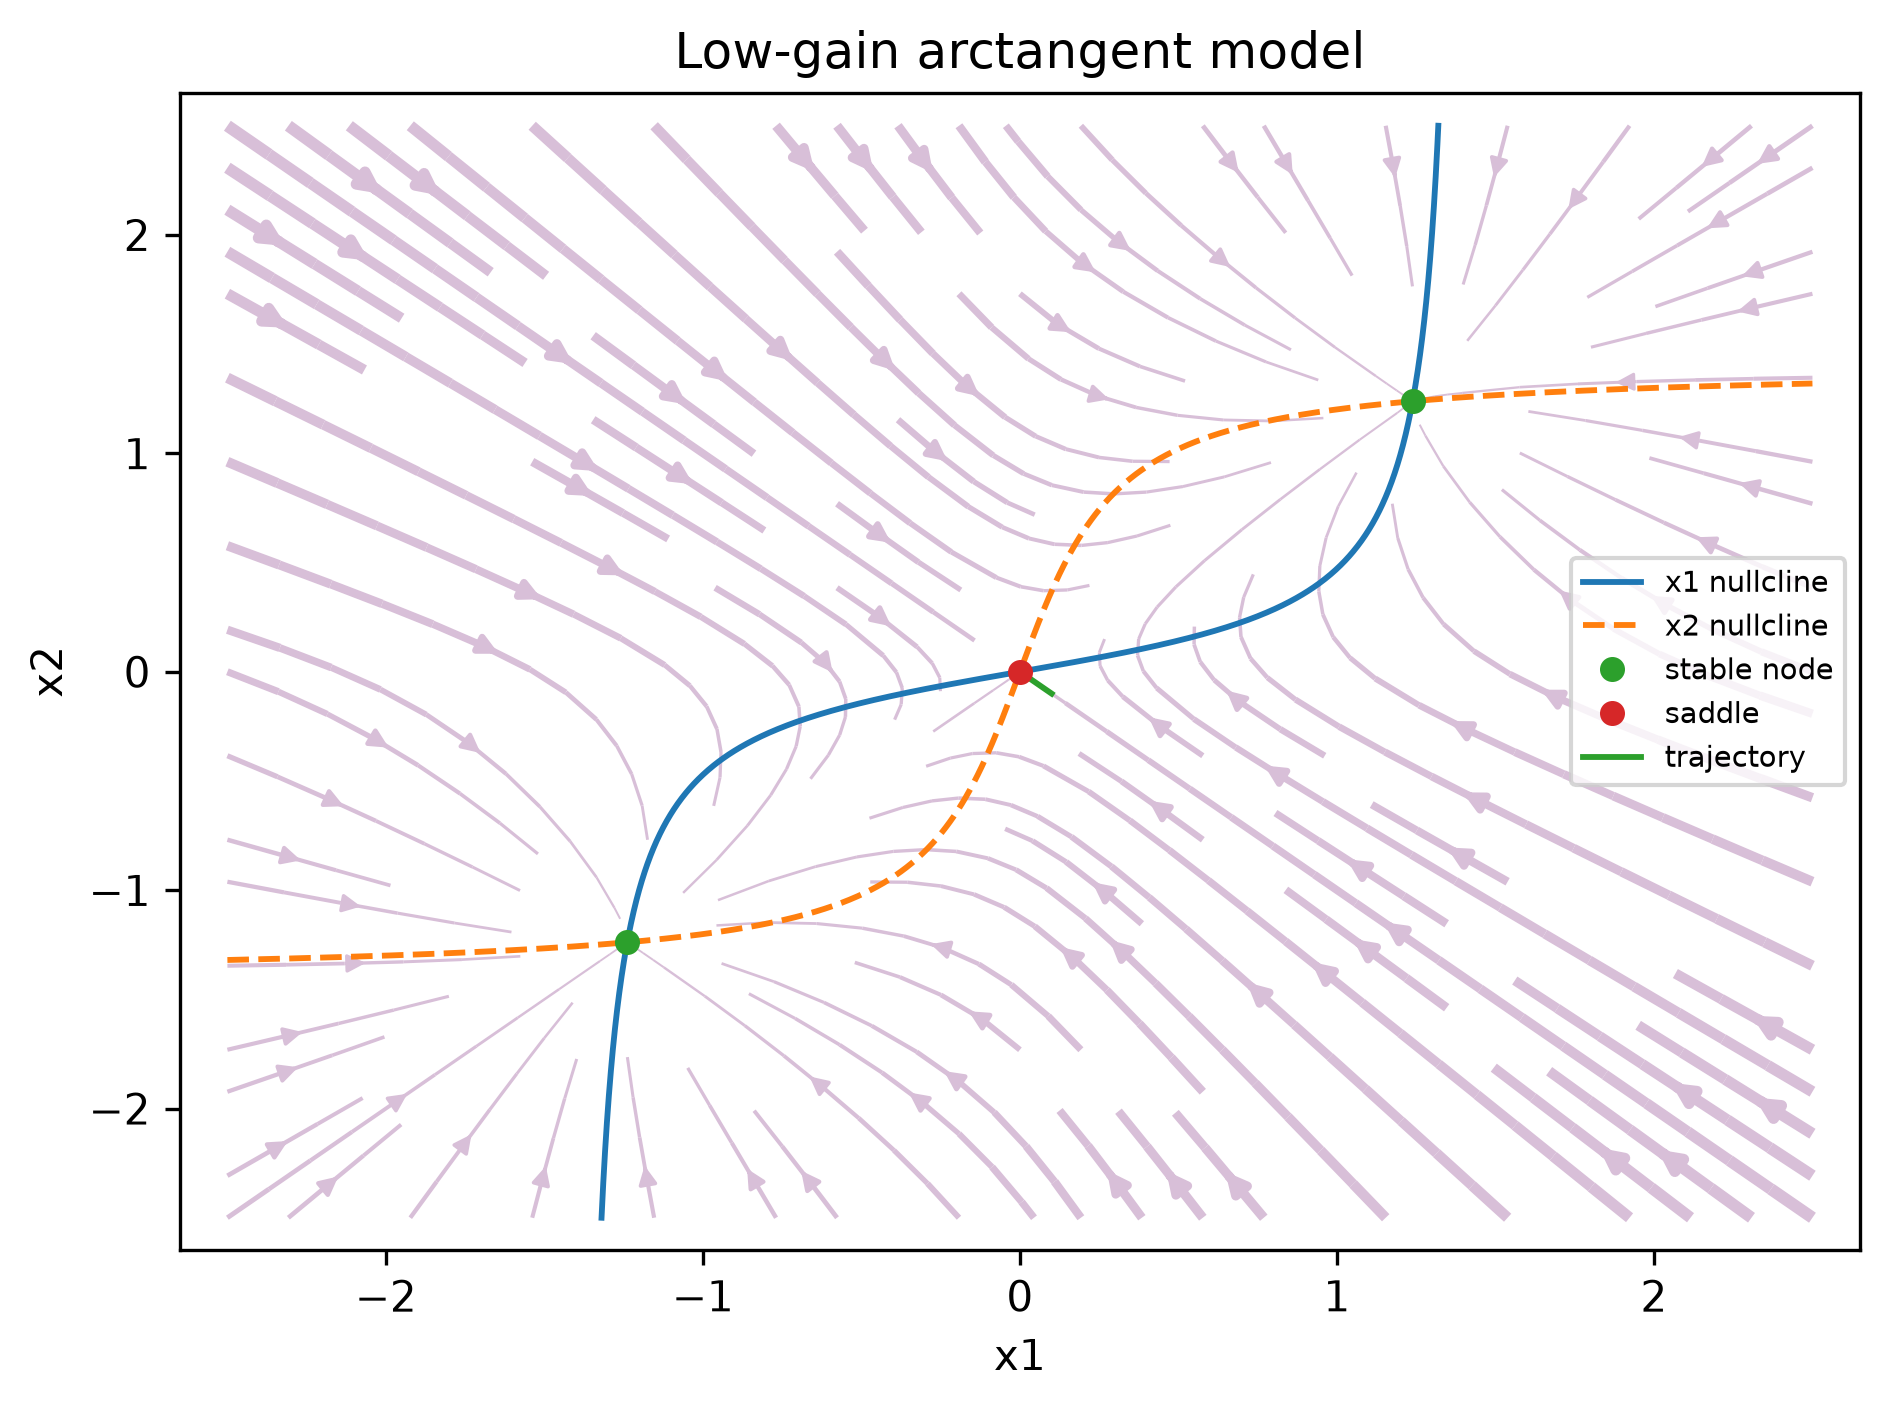

stable node: (-1.2388, -1.2388)
     saddle: ( 0.0000,  0.0000)
stable node: ( 1.2388,  1.2388)


In [2]:
low_gain_figure, low_gain_axis = plt.subplots(figsize=(6.4, 4.8))
draw_phase_plane(low_gain_axis, low_gain_atan_model, title="Low-gain arctangent model")
low_gain_equilibria = [
    (point, classify_equilibrium(low_gain_atan_model, point))
    for point in find_equilibria(low_gain_atan_model)
]
low_gain_figure.tight_layout()
plt.show()
for point, kind in low_gain_equilibria:
    print(f"{kind:>11}: ({point[0]: .4f}, {point[1]: .4f})")

## 3. 高增益 arctan 模型

将低增益 arctan 模型的增益从 2 提高到 100，其余参数不变。激活函数在原点附近变得更陡，更快进入饱和区，零流线也更接近阶跃形状。

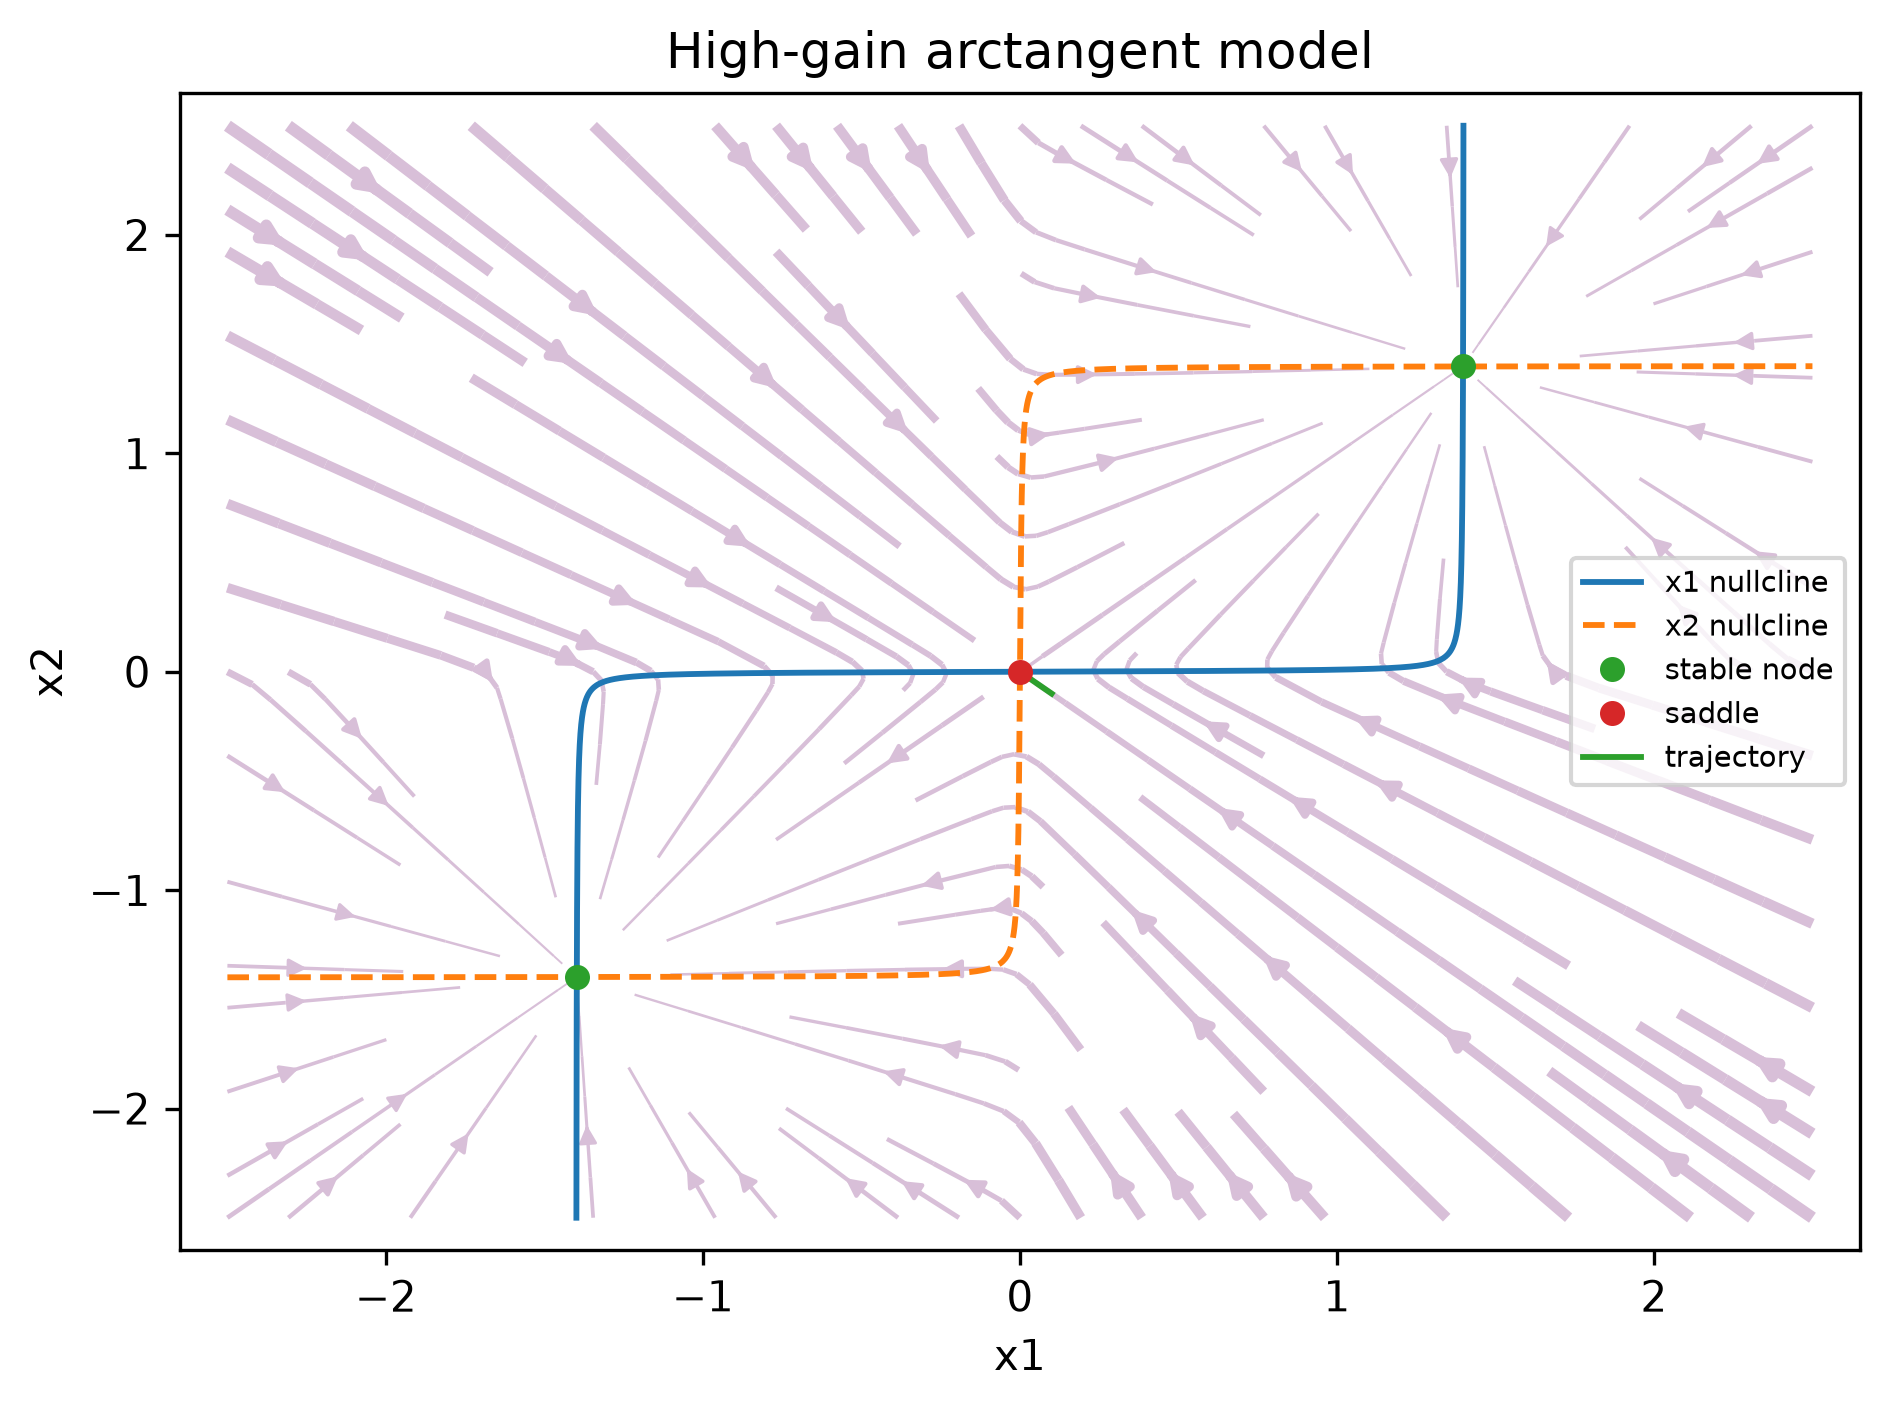

In [5]:
high_gain_figure, high_gain_axis = plt.subplots(figsize=(6.4, 4.8))
draw_phase_plane(high_gain_axis, high_gain_atan_model, title="High-gain arctangent model")
high_gain_equilibria = find_equilibria(high_gain_atan_model)
high_gain_figure.tight_layout()
plt.show()

## 4. sigmoid 模型：相平面与时间序列

两幅子图的耦合权重均为 2。左图使用增益 0.8，展示相平面：sigmoid 输出始终为正，两条零流线在第一象限相交，窗口内只有一个稳定结点。

右图将增益提高到 4，展示从 $(10,-1)$ 出发的时间序列。状态经过短暂的快速变化后趋近约 $(2,2)$。横轴使用对称对数刻度，便于查看早期变化和长时间稳态。

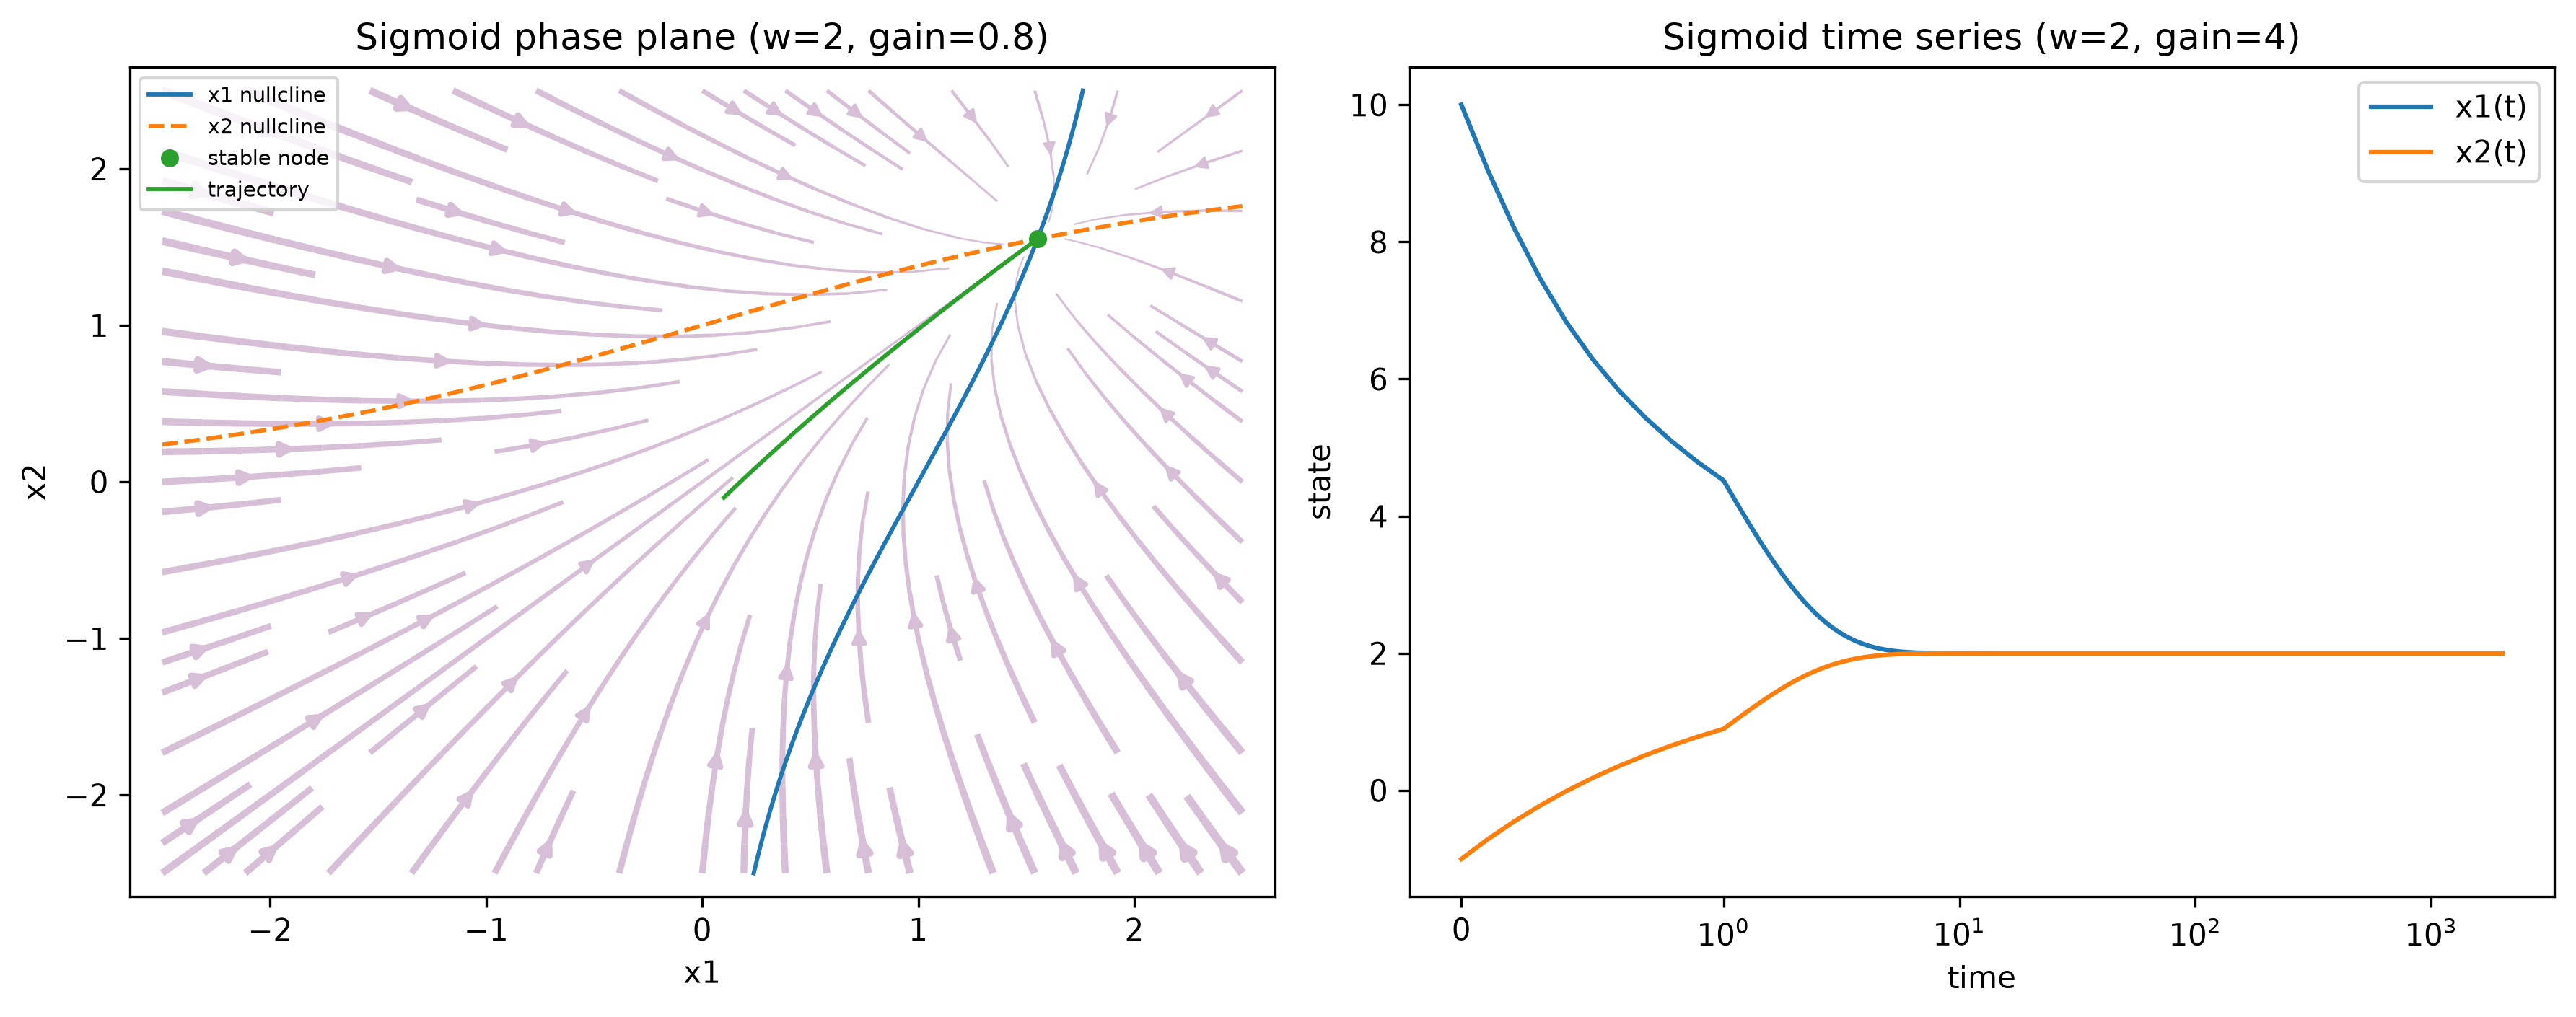

最终状态： [1.99932749 1.99932749]


In [3]:
sigmoid_figure, (sigmoid_phase_axis, sigmoid_time_axis) = plt.subplots(1, 2, figsize=(12, 4.8))
draw_phase_plane(
    sigmoid_phase_axis,
    sigmoid_phase_model,
    names=("x1", "x2"),
    title="Sigmoid phase plane (w=2, gain=0.8)",
)
sigmoid_equilibria = find_equilibria(sigmoid_phase_model)

sigmoid_solution = integrate(sigmoid_time_model, [10.0, -1.0], 2000.0, samples=20001)
sigmoid_time_axis.plot(sigmoid_solution.t, sigmoid_solution.y[0], label="x1(t)")
sigmoid_time_axis.plot(sigmoid_solution.t, sigmoid_solution.y[1], label="x2(t)")
sigmoid_time_axis.set_xscale("symlog", linthresh=1)
sigmoid_time_axis.set(xlabel="time", ylabel="state", title="Sigmoid time series (w=2, gain=4)")
sigmoid_time_axis.legend()
sigmoid_figure.tight_layout()
plt.show()
print("最终状态：", sigmoid_solution.y[:, -1])

## 5. tanh 模型：相互抑制与临界衰减

左图取 $w=-5$、增益 0.4，两个神经元互相抑制。原点是鞍点，轨迹沿稳定方向接近原点，沿不稳定方向则会离开。

右图取 $w=1$、增益 1，两图均使用 $\tau=1$。此时沿 $x_1=x_2$ 方向，原点附近的线性反馈恰好抵消漏电项，Jacobian 矩阵有一个零特征值，原点是非双曲平衡点。从 $(10,-1)$ 出发的轨迹先快速靠近对角线，再以代数速度缓慢趋近零。

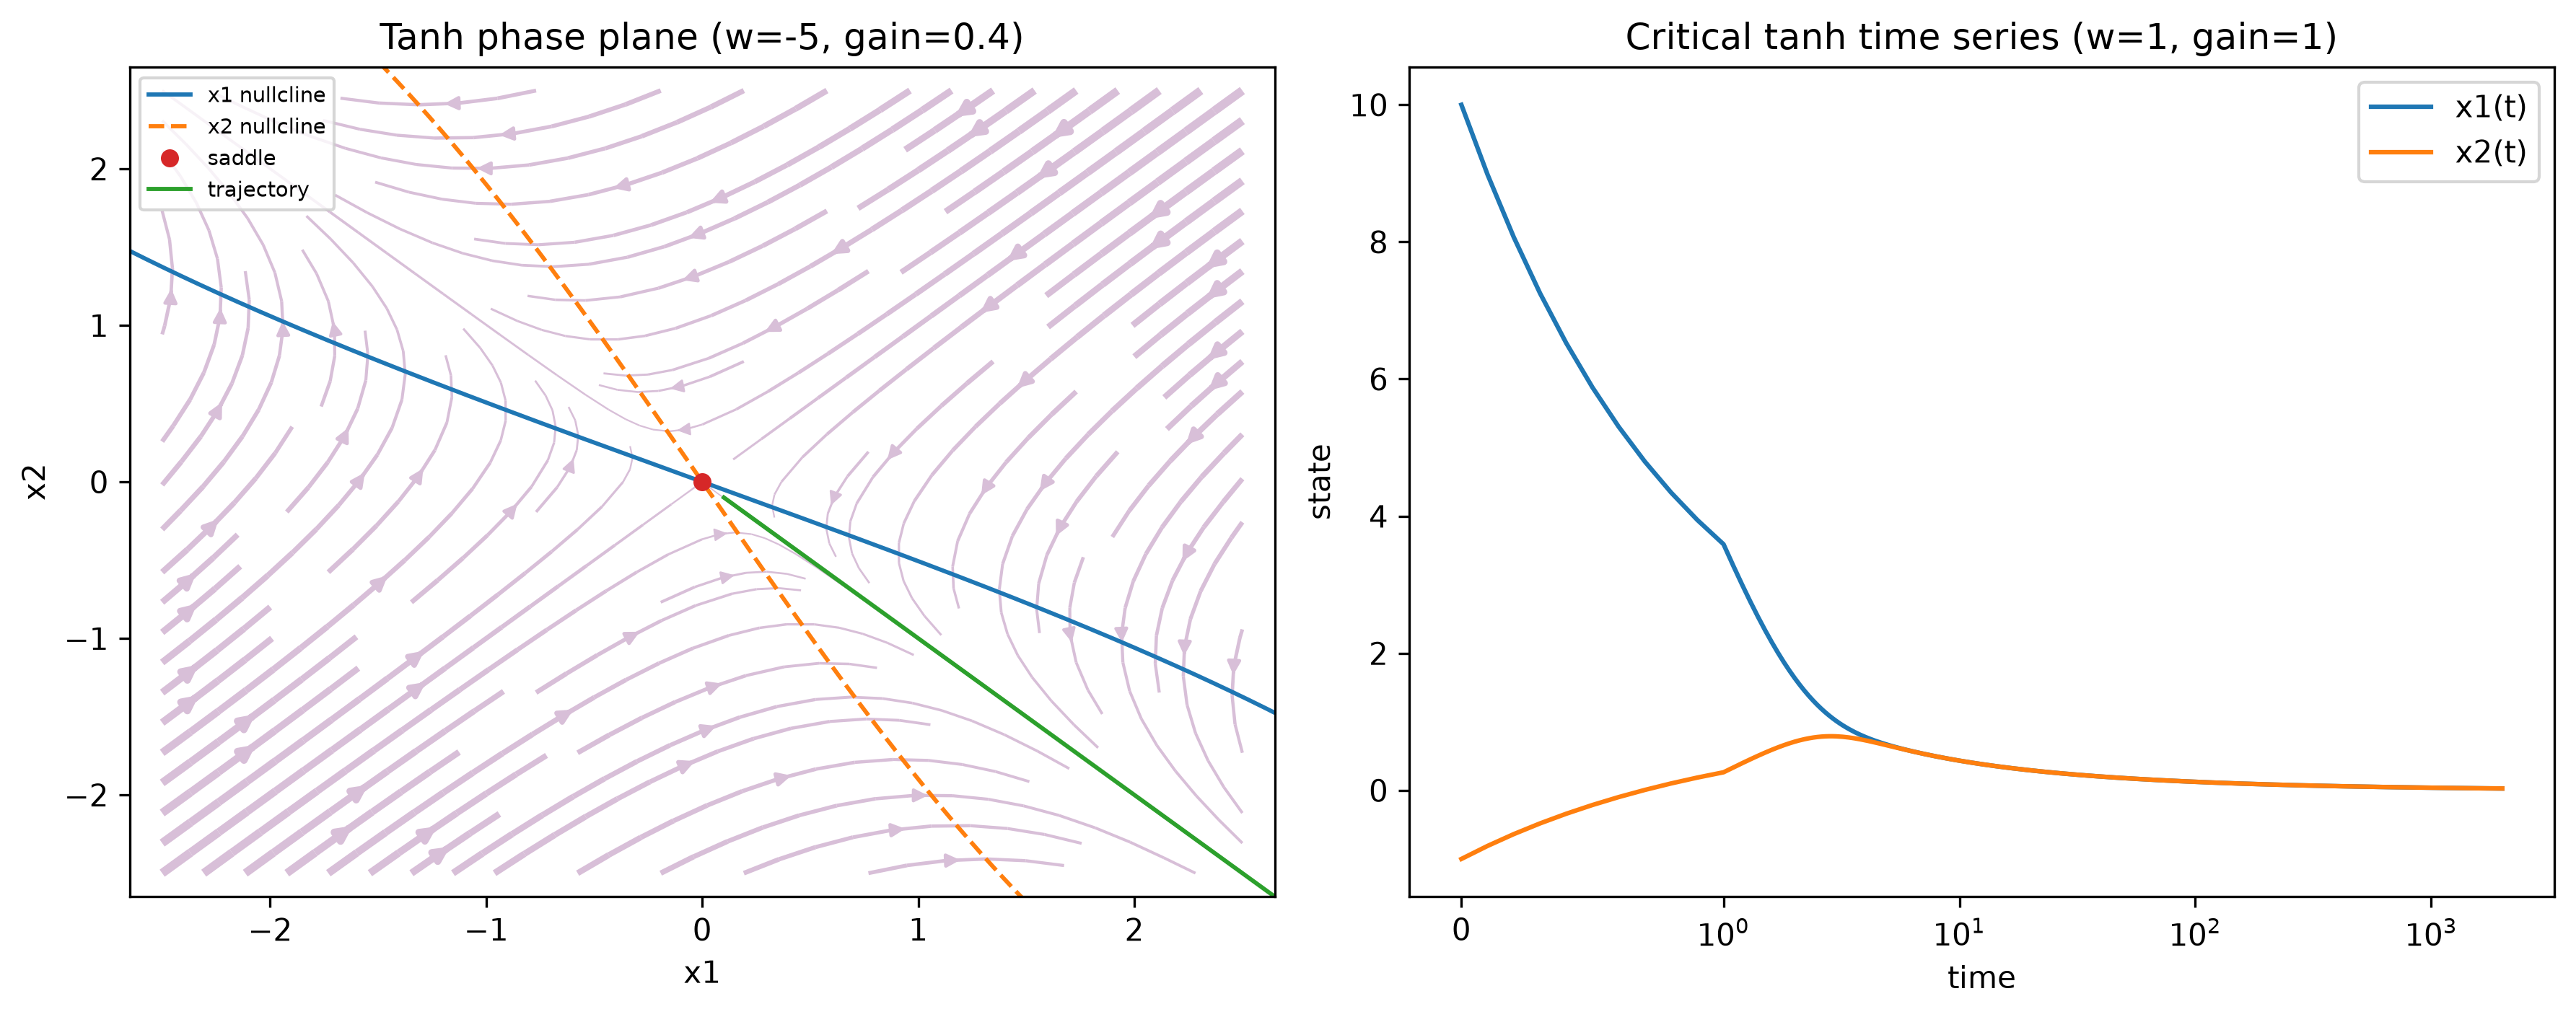

最终状态： [0.02742271 0.02742271]


In [4]:
tanh_figure, (tanh_phase_axis, tanh_time_axis) = plt.subplots(1, 2, figsize=(12, 4.8))
draw_phase_plane(
    tanh_phase_axis,
    inhibitory_tanh_model,
    names=("x1", "x2"),
    title="Tanh phase plane (w=-5, gain=0.4)",
)
inhibitory_tanh_equilibria = find_equilibria(inhibitory_tanh_model)

critical_tanh_solution = integrate(critical_tanh_model, [10.0, -1.0], 2000.0, samples=20001)
tanh_time_axis.plot(critical_tanh_solution.t, critical_tanh_solution.y[0], label="x1(t)")
tanh_time_axis.plot(critical_tanh_solution.t, critical_tanh_solution.y[1], label="x2(t)")
tanh_time_axis.set_xscale("symlog", linthresh=1)
tanh_time_axis.set(xlabel="time", ylabel="state", title="Critical tanh time series (w=1, gain=1)")
tanh_time_axis.legend()
tanh_figure.tight_layout()
plt.show()
print("最终状态：", critical_tanh_solution.y[:, -1])

## 6. Hopfield 能量景观

用 $V_1,V_2$ 表示两个神经元经过激活函数后的输出。取 $\lambda=1.4$，在 $-1<V_1,V_2<1$ 内绘制能量函数：

$$E(V_1,V_2)=-V_1V_2-\frac{4}{\pi^2\lambda}\left[\ln\cos(\pi V_1/2)+\ln\cos(\pi V_2/2)\right].$$

两个低能量区域对应两个对称稳定状态。该能量函数使用特定的 arctan 参数，不能直接作为前面低增益或高增益模型的能量函数。

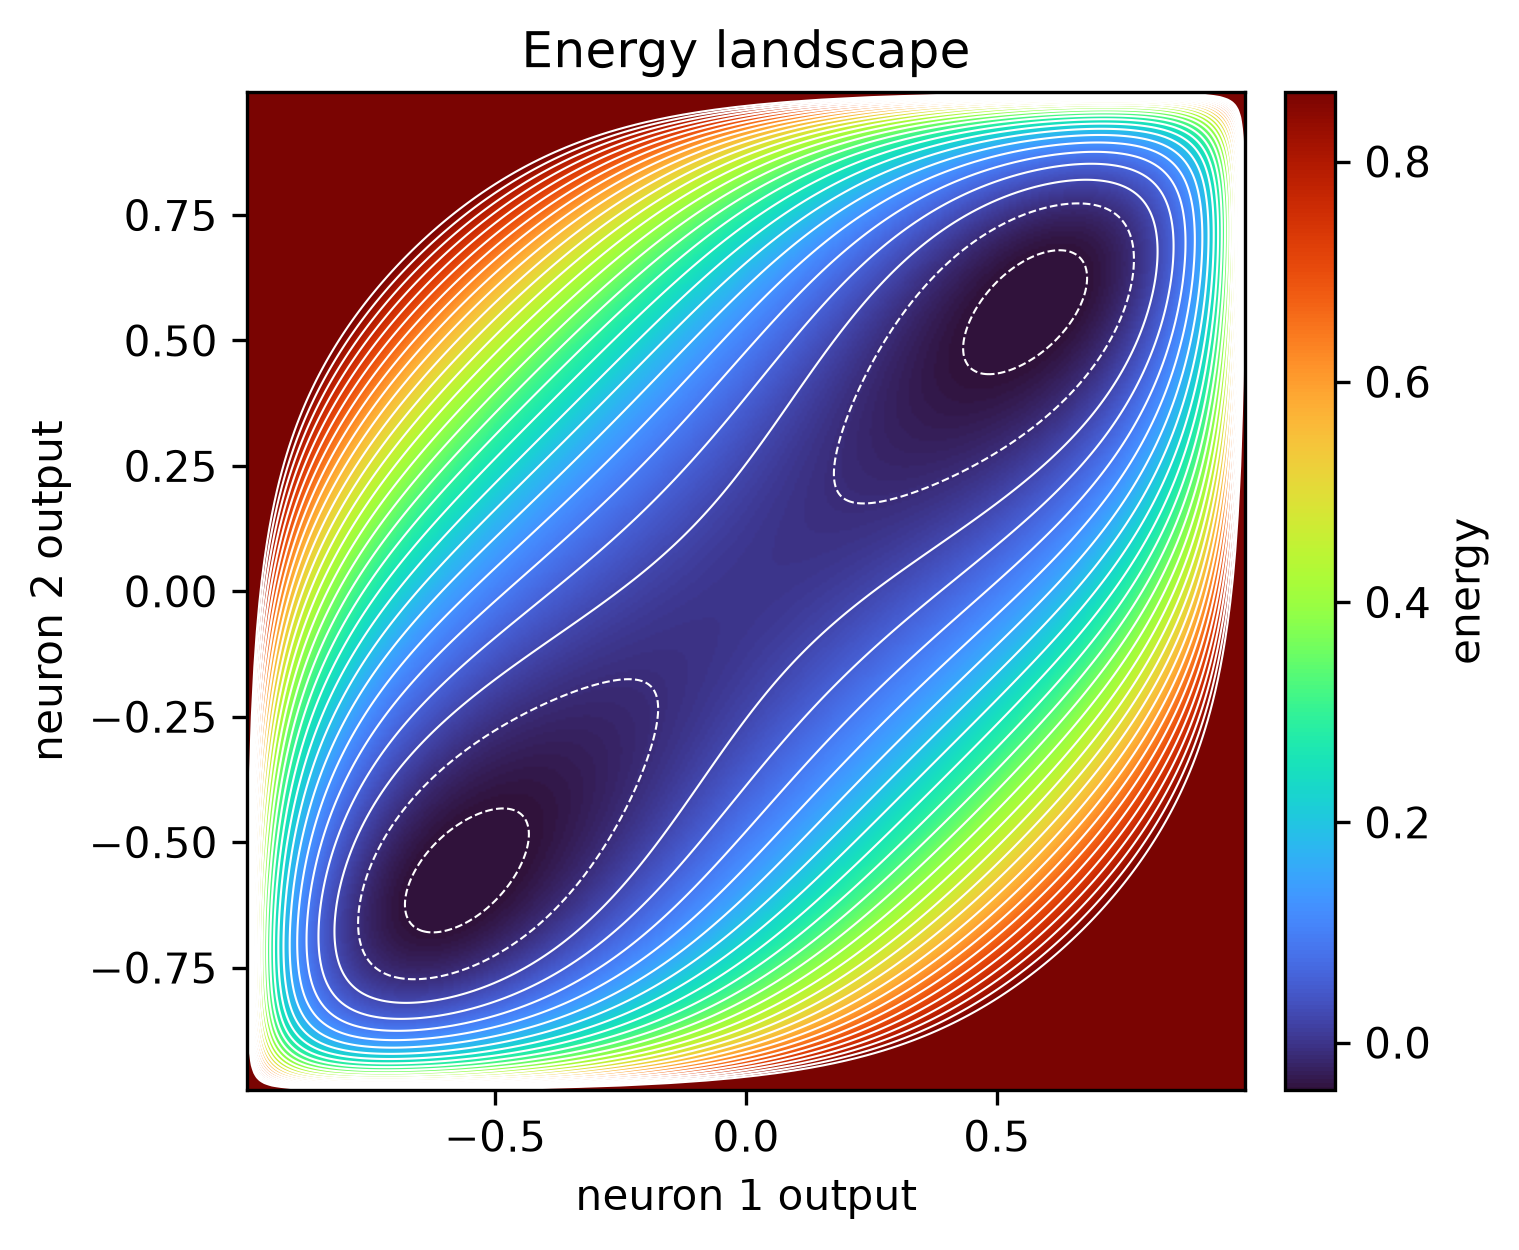

In [6]:
energy_figure, energy_axis = plt.subplots(figsize=(5.2, 5.2))
energy_image = draw_energy_landscape(energy_axis)
energy_colorbar_axis = energy_axis.inset_axes([1.04, 0, 0.05, 1])
energy_figure.colorbar(energy_image, cax=energy_colorbar_axis, label="energy")
energy_figure.tight_layout()
plt.show()

## 可选扩展

任选一项修改，并同时记录平衡点位置、稳定性和轨迹变化：

- 连续改变 arctan 增益，观察零流线从平滑曲线过渡到近似阶跃；
- 改变耦合权重的符号，比较互激与互抑模型；
- 加入非零外部输入 $I$，观察对称吸引子如何发生偏移。